# Actual Queue Simulator Repeatability (BCLF)

Pick one already-simulated case from `data/bandpass_coupled_line_filter_export`, submit the same variable setting to the actual queue (`queue/pending` query job), wait for completion, then compare returned result with the original exported `.s2p`.


In [1]:
from __future__ import annotations

from pathlib import Path
import json
import re
import time
import hashlib
import uuid
import numpy as np

def _find_repo_root(start: Path) -> Path:
    cur = start.resolve()
    for candidate in [cur, *cur.parents]:
        if (candidate / 'data').exists() and (candidate / 'queue').exists():
            return candidate
    raise RuntimeError('Could not locate repo root containing data/ and queue/')

REPO_ROOT = _find_repo_root(Path.cwd())
ORIGINAL_EXPORT_DIR = REPO_ROOT / 'data' / 'bandpass_coupled_line_filter_export'
QUEUE_ROOT = REPO_ROOT / 'queue'

REQUIRED_VARS = ['L', 'L1', 'L2', 'W', 'W1', 'W2', 'S1', 'S2']
VARIABLE_ORDER = ['L', 'L1', 'L2', 'W', 'W1', 'W2', 'S1', 'S2']
TEMPLATE_NAME = 'bclf_template_v1'
METRICS = ['max_s11_db']
TIMEOUT_SEC = 3600
POLL_SEC = 2


In [2]:
def _decode_value(token: str) -> float:
    return float(token.replace('m', '-').replace('d', '.'))

def parse_bclf_vars_from_filename(filename: str) -> dict[str, float]:
    stem = Path(filename).stem
    pairs = re.findall(r'_(L1|L2|W1|W2|S1|S2|L|W)_([md0-9]+)', stem)
    out: dict[str, float] = {}
    for key, raw in pairs:
        out[key] = _decode_value(raw)
    return out

def pick_first_valid_case(root: Path) -> tuple[Path, dict[str, float]]:
    for path in sorted(root.glob('*.s2p')):
        parsed = parse_bclf_vars_from_filename(path.name)
        if all(k in parsed for k in REQUIRED_VARS):
            return path, parsed
    raise RuntimeError(f'No valid .s2p file with required vars in {root}')

def ensure_queue_dirs(root: Path) -> None:
    for sub in ['pending', 'running', 'done', 'failed', 'results', 'archive']:
        (root / sub).mkdir(parents=True, exist_ok=True)

def build_job_payload(job_id: str, vars_mm: dict[str, float]) -> dict:
    vars_with_units = {k: f"{float(vars_mm[k]):g}mm" for k in VARIABLE_ORDER}
    return {
        'job_id': job_id,
        'template_name': TEMPLATE_NAME,
        'variables': vars_with_units,
        'output_filename': f"{job_id}.s2p",
        'submit_time': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
        'metrics_to_extract': METRICS,
        'design_name': None,
        'setup_name': None,
        'sweep_name': None,
        'artifact_options': {},
        'retry_count': 0,
    }

def submit_query_job(queue_root: Path, payload: dict) -> Path:
    ensure_queue_dirs(queue_root)
    path = queue_root / 'pending' / f"{payload['job_id']}.json"
    with path.open('w', encoding='utf-8') as f:
        json.dump(payload, f, ensure_ascii=True, indent=2)
    return path

def wait_result(queue_root: Path, job_id: str, timeout_sec: float, poll_sec: float) -> tuple[str, Path, dict]:
    done_path = queue_root / 'done' / f"{job_id}.result.json"
    fail_path = queue_root / 'failed' / f"{job_id}.result.json"
    t0 = time.time()
    while True:
        if done_path.exists():
            with done_path.open('r', encoding='utf-8') as f:
                return 'done', done_path, json.load(f)
        if fail_path.exists():
            with fail_path.open('r', encoding='utf-8') as f:
                return 'failed', fail_path, json.load(f)
        if (time.time() - t0) > timeout_sec:
            raise TimeoutError(f'Job timeout after {timeout_sec}s: {job_id}')
        time.sleep(poll_sec)

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def parse_touchstone_numeric_rows(path: Path) -> np.ndarray:
    rows = []
    with path.open('r', encoding='utf-8', errors='ignore') as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith('!') or line.startswith('#'):
                continue
            parts = line.split()
            try:
                vals = [float(x) for x in parts]
            except ValueError:
                continue
            rows.append(vals)
    if not rows:
        raise ValueError(f'No numeric rows parsed from {path}')
    return np.asarray(rows, dtype=float)


def _encode_value_for_filename(v: float) -> str:
    fv = float(v)
    # Match existing ext naming: keep one decimal for integer-like values (8.0 -> 8d0).
    if fv.is_integer():
        s = f"{fv:.1f}"
    else:
        s = f"{fv:g}"
    return s.replace('-', 'm').replace('.', 'd')

def build_ext_filename(vars_mm: dict[str, float]) -> str:
    prefix = 'Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter'
    parts = [f"{k}_{_encode_value_for_filename(vars_mm[k])}" for k in VARIABLE_ORDER]
    return prefix + '_' + '_'.join(parts) + '.s2p'

def expected_ext_path(export_root: Path, vars_mm: dict[str, float]) -> Path:
    return export_root / 'ext' / build_ext_filename(vars_mm)




In [3]:
source_s2p, parsed_vars = pick_first_valid_case(ORIGINAL_EXPORT_DIR)
ext_s2p = expected_ext_path(ORIGINAL_EXPORT_DIR, parsed_vars)

print('Selected original case:', source_s2p.name)
print('Parsed vars:', {k: parsed_vars[k] for k in VARIABLE_ORDER})
print('Expected ext file:', ext_s2p)

if ext_s2p.exists():
    print('Ext file already exists. Skip submitting new job.')
    job_id = None
    payload = None
    job_file = None
    new_s2p = ext_s2p
else:
    job_id = f"bclf_query_{time.strftime('%Y%m%dT%H%M%S', time.gmtime())}_{uuid.uuid4().hex[:6]}"
    payload = build_job_payload(job_id, parsed_vars)
    job_file = submit_query_job(QUEUE_ROOT, payload)
    print('Submitted job json:', job_file)
    print('Job ID:', job_id)



Selected original case: Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p
Parsed vars: {'L': 7.7, 'L1': 8.0, 'L2': 7.8, 'W': 0.9, 'W1': 0.7, 'W2': 0.9, 'S1': 0.13, 'S2': 0.55}
Expected ext file: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p
Ext file already exists. Skip submitting new job.


In [4]:
if job_id is None:
    print('Using existing ext touchstone:', new_s2p)
else:
    status, result_path, result_payload = wait_result(QUEUE_ROOT, job_id, TIMEOUT_SEC, POLL_SEC)
    print('Final status:', status)
    print('Result json:', result_path)

    if status != 'done':
        raise RuntimeError(f"Simulation failed: {result_payload.get('error_message', result_payload)}")

    touchstone_rel = (result_payload.get('artifacts') or {}).get('touchstone')
    if not touchstone_rel:
        raise RuntimeError('No touchstone artifact path in result payload')

    generated_s2p = QUEUE_ROOT / touchstone_rel
    if not generated_s2p.exists():
        raise FileNotFoundError(f'Touchstone artifact missing: {generated_s2p}')

    print('Generated touchstone:', generated_s2p)

    target_ext = expected_ext_path(ORIGINAL_EXPORT_DIR, parsed_vars)
    target_ext.parent.mkdir(parents=True, exist_ok=True)
    generated_s2p.replace(target_ext)
    new_s2p = target_ext
    print('Moved to ext:', new_s2p)



Using existing ext touchstone: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p


In [5]:
src_hash = sha256_file(source_s2p)
new_hash = sha256_file(new_s2p)
hash_equal = (src_hash == new_hash)

src_rows = parse_touchstone_numeric_rows(source_s2p)
new_rows = parse_touchstone_numeric_rows(new_s2p)
same_shape = (src_rows.shape == new_rows.shape)

if same_shape:
    max_abs_diff = float(np.max(np.abs(src_rows - new_rows)))
    rows_allclose = bool(np.allclose(src_rows, new_rows, atol=1e-12, rtol=0.0))
else:
    max_abs_diff = float('nan')
    rows_allclose = False

print('original_file:', source_s2p)
print('new_file:', new_s2p)
print('sha256_equal:', hash_equal)
print('original_sha256:', src_hash)
print('new_sha256:', new_hash)
print('same_numeric_shape:', same_shape, 'shape_original=', src_rows.shape, 'shape_new=', new_rows.shape)
print('numeric_rows_allclose(atol=1e-12,rtol=0):', rows_allclose)
print('max_abs_diff_numeric_rows:', max_abs_diff)


original_file: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p
new_file: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p
sha256_equal: False
original_sha256: c2d63edd5f2c7b049f3051dde25f9504cace1411e97c41147c7774ae0983f424
new_sha256: 5ee092ac200c4d2f0832f8974d30a7aa475fce5864fc4f2443a68e0d99466744
same_numeric_shape: True shape_original= (401, 9) shape_new= (401, 9)
numeric_rows_allclose(atol=1e-12,rtol=0): False
max_abs_diff_numeric_rows: 358.89609850363


Original (outside ext): /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p
Expected ext: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d7_L1_8d0_L2_7d8_W_0d9_W1_0d7_W2_0d9_S1_0d13_S2_0d55.s2p
same_numeric_shape: True shape_original= (401, 9) shape_ext= (401, 9)
original_format: MA
expected_ext_format: MA
S11 max|diff| dB: 27.435166424229877 mean|diff| dB: 1.0271427079463848
S21 max|diff| dB: 2.2219500677813144 mean|diff| dB: 1.1410344017611356


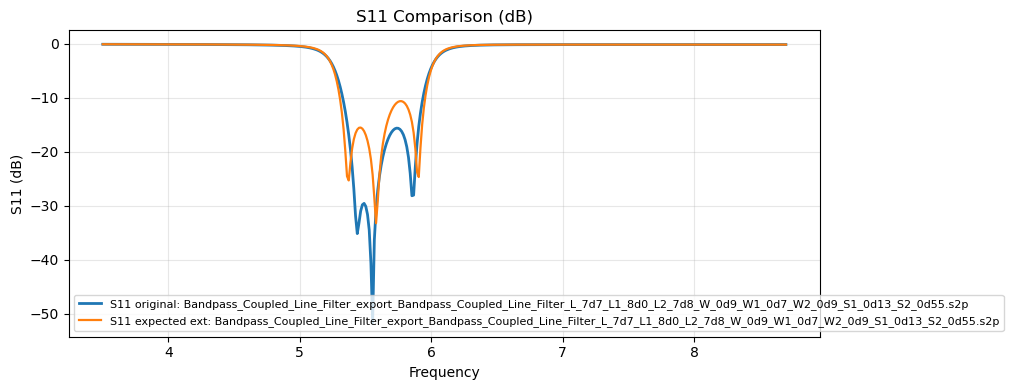

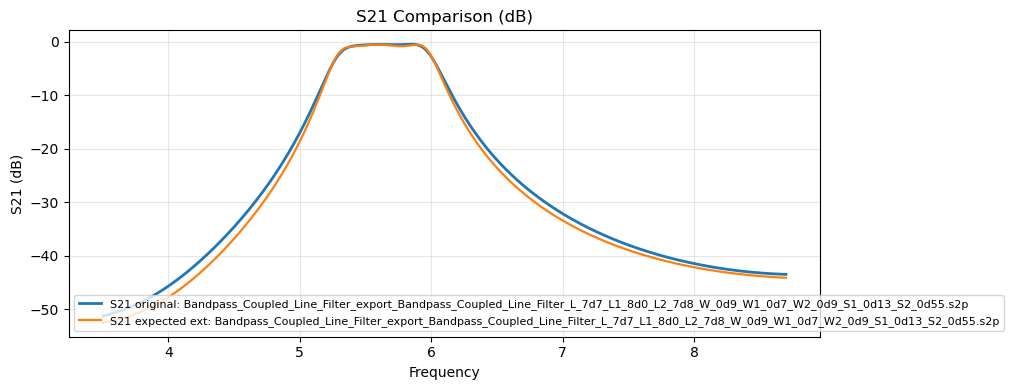

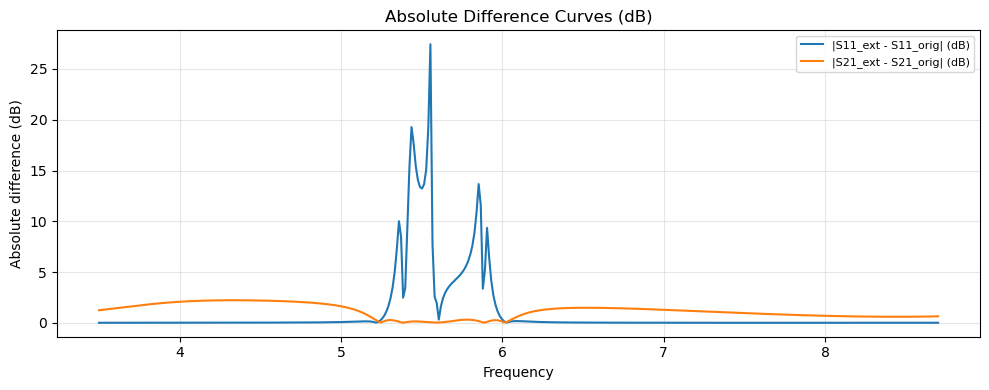

In [6]:
import matplotlib.pyplot as plt

# One-vs-one only: original (outside ext) vs expected ext file for the same parameters.
expected_s2p = expected_ext_path(ORIGINAL_EXPORT_DIR, parsed_vars)

print('Original (outside ext):', source_s2p)
print('Expected ext:', expected_s2p)

if not expected_s2p.exists():
    raise FileNotFoundError(f'Expected ext file does not exist: {expected_s2p}')

orig_rows = parse_touchstone_numeric_rows(source_s2p)
ext_rows = parse_touchstone_numeric_rows(expected_s2p)

same_shape = orig_rows.shape == ext_rows.shape
print('same_numeric_shape:', same_shape, 'shape_original=', orig_rows.shape, 'shape_ext=', ext_rows.shape)
if not same_shape:
    raise RuntimeError('Original and expected ext files do not have the same numeric shape.')

# Touchstone 2-port numeric columns are expected as:
# f, S11(a,b), S21(a,b), S12(a,b), S22(a,b)
# where (a,b) meaning depends on format RI/MA/DB from the '#' option line.
def parse_touchstone_format(path: Path) -> str:
    with path.open('r', encoding='utf-8', errors='ignore') as f:
        for raw in f:
            line = raw.strip()
            if line.startswith('#'):
                parts = line[1:].split()
                up = [p.upper() for p in parts]
                for cand in ('RI', 'MA', 'DB'):
                    if cand in up:
                        return cand
    # Default Touchstone interpretation fallback.
    return 'MA'

def pair_to_complex(a: np.ndarray, b: np.ndarray, fmt: str) -> np.ndarray:
    fmt = fmt.upper()
    if fmt == 'RI':
        return a + 1j * b
    if fmt == 'MA':
        return a * np.exp(1j * np.deg2rad(b))
    if fmt == 'DB':
        mag = np.power(10.0, a / 20.0)
        return mag * np.exp(1j * np.deg2rad(b))
    raise ValueError(f'Unsupported Touchstone format: {fmt}')

def extract_s11_s21_db(rows: np.ndarray, fmt: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if rows.shape[1] < 9:
        raise ValueError(f'Expected at least 9 numeric columns for 2-port data, got {rows.shape[1]}')
    f = rows[:, 0]
    s11 = pair_to_complex(rows[:, 1], rows[:, 2], fmt)
    s21 = pair_to_complex(rows[:, 3], rows[:, 4], fmt)
    s11_db = 20.0 * np.log10(np.maximum(np.abs(s11), 1e-300))
    s21_db = 20.0 * np.log10(np.maximum(np.abs(s21), 1e-300))
    return f, s11_db, s21_db

orig_fmt = parse_touchstone_format(source_s2p)
ext_fmt = parse_touchstone_format(expected_s2p)
print('original_format:', orig_fmt)
print('expected_ext_format:', ext_fmt)

f_orig, s11_orig_db, s21_orig_db = extract_s11_s21_db(orig_rows, orig_fmt)
f_ext, s11_ext_db, s21_ext_db = extract_s11_s21_db(ext_rows, ext_fmt)

# For safety, check frequency alignment.
if f_orig.shape != f_ext.shape or not np.allclose(f_orig, f_ext, atol=1e-12, rtol=0.0):
    raise RuntimeError('Frequency grids differ between original and expected ext files.')

s11_abs_err = np.abs(s11_ext_db - s11_orig_db)
s21_abs_err = np.abs(s21_ext_db - s21_orig_db)
print('S11 max|diff| dB:', float(np.max(s11_abs_err)), 'mean|diff| dB:', float(np.mean(s11_abs_err)))
print('S21 max|diff| dB:', float(np.max(s21_abs_err)), 'mean|diff| dB:', float(np.mean(s21_abs_err)))

# Plot S11 overlay
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(f_orig, s11_orig_db, label=f'S11 original: {source_s2p.name}', linewidth=2)
ax.plot(f_ext, s11_ext_db, label=f'S11 expected ext: {expected_s2p.name}', linewidth=1.6)
ax.set_title('S11 Comparison (dB)')
ax.set_xlabel('Frequency')
ax.set_ylabel('S11 (dB)')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Plot S21 overlay
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(f_orig, s21_orig_db, label=f'S21 original: {source_s2p.name}', linewidth=2)
ax.plot(f_ext, s21_ext_db, label=f'S21 expected ext: {expected_s2p.name}', linewidth=1.6)
ax.set_title('S21 Comparison (dB)')
ax.set_xlabel('Frequency')
ax.set_ylabel('S21 (dB)')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Plot absolute error curves in dB
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(f_orig, s11_abs_err, label='|S11_ext - S11_orig| (dB)')
ax.plot(f_orig, s21_abs_err, label='|S21_ext - S21_orig| (dB)')
ax.set_title('Absolute Difference Curves (dB)')
ax.set_xlabel('Frequency')
ax.set_ylabel('Absolute difference (dB)')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()



## Fake Simulator Repeatability Experiment Summary (BCLF)

### Experiment Setup
- Baseline file: one original BCLF Touchstone case from `data/bandpass_coupled_line_filter_export` (outside `ext`).
- Comparison file: the parameter-matched expected file in `data/bandpass_coupled_line_filter_export/ext`.
- Matching variables: `L, L1, L2, W, W1, W2, S1, S2`.
- Comparison method:
  - Numeric row shape check
  - S-parameter parsing from Touchstone format (`RI` / `MA` / `DB`)
  - Overlay plots for `S11` and `S21` in dB
  - Absolute difference curves vs frequency

### Observations
- **S11**
  - Curves overlap well outside the resonant region.
  - Around the notch region (~5.3–5.9 GHz), there is noticeable depth mismatch.
  - Original has a deeper minimum near the center of the notch, while the expected ext case is shallower.
- **S21**
  - Both curves show the same overall passband and roll-off shape.
  - A small but systematic offset appears in parts of transition/stopband.
  - Expected ext is slightly lower in some frequency ranges.

### Conclusion
- The compared pair is qualitatively consistent (same band structure and trend), but not numerically identical.
- The largest discrepancy is in **S11 notch depth**; **S21** differences are smaller and mostly offset-like.

### Notes
- Header metadata can differ (generation timestamp, `Sweep` vs `Sweep1`) even when design variables match.
- Repeatability reporting should include max/mean `|ΔS11|`, `|ΔS21|` and frequency of peak deviation.

